# Hemispheric lateralisation of a hippocampal spike: corrected simulation (2026-10-13)

This notebook replaces `sim_spikes.ipynb`. It simulates an interictal spike at a source in the
hippocampus, projects it to the 306-channel Vectorview array, adds real resting-state MEG noise,
reconstructs the sources, and asks whether the **hemisphere** of the source is recovered.

Every correction relative to the old notebook is tagged in comments as **`[FIX n]`**, numbered as in
the review of 2026-10-13:

| # | Problem in `sim_spikes.ipynb` | Correction here |
|---|---|---|
| 1 | Simulated vertex (`VERTEX`, global) differed from the scored vertex (`VERTECES=[-75]`, a Left-Amygdala point) | One `SourceDef` object carries the position used **both** to simulate and to score |
| 2 | Results written to `SNR_RH_2_test_ratio.txt`, plots read `SNR_LH_2_test_ratio.csv` | One `RUN_TAG`; config + results saved together, plots read what this run wrote |
| 3 | Spike handled at 2048 Hz, noise at 1000 Hz | Everything at the noise `sfreq` (1000 Hz, same as the sEEG the spike came from) |
| 4 | Noise covariance window (0–0.5 s) overlapped the spike onset (0.4 s) | Covariance from a separate, signal-free noise segment |
| 5 | Orientations restricted to the positive octant | Uniform sampling of the full hemisphere of directions (sign-equivalent) |
| 6 | `cos_xz = 1` repeated 4×, only 13/16 distinct orientations | Fibonacci sampling → all orientations distinct, equal weight |
| 7 | Axis names "xy"/"xz" were really azimuth/polar angle | Orientations described explicitly: radial fraction, tangential azimuth, and MRI x/y/z shares |
| 8 | Orientation in MRI frame, not mirrored between hemispheres | Local radial/tangential frame; right-hemisphere orientations are the exact mirror (x → −x) of the left |
| 9 | SNR from max *positive* value mixing T and T/m | SNR defined on **whitened** data (mag + grad jointly, unit-free) |
| 10 | One fixed noise segment for every run | Independent random noise epochs per repetition → confidence intervals |
| 11 | Separate grad/mag MNE averaged; MNE only; same model to simulate and invert | Joint whitened inverse; MNE, dSPM, sLORETA (+ dipole fit subset); true sources off the inverse grid |
| 12 | Vertex-count ratio (÷0, unbounded, cortex-dominated) and centroid distance | Amplitude laterality index in a mesial-temporal ROI and over whole hemispheres; peak-based hemisphere and peak error |

The old vertex-count ratio is still computed (safely) on the new data, so the two metrics can be compared.

**Additional:** a dedicated section quantifies bias from the **spatial distribution of the noise**.

In [1]:
import os, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal
import matplotlib.pyplot as plt
import mne
from mne.minimum_norm.inverse import _assemble_kernel, combine_xyz  # used to apply the (linear) inverse fast

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("MNE", mne.__version__)

MNE 1.13.2


## 0. Configuration
All paths and parameters in one place. **[FIX 2]** every output file name derives from `RUN_TAG`.

In [2]:
RUN_TAG = "261013"
HERE = Path(os.environ.get("SIM_DIR", ".")).resolve()
OUT = HERE / f"results_{RUN_TAG}"
OUT.mkdir(exist_ok=True)

# fsaverage template (same template as the old notebook). Set SUBJECTS_DIR_SIM to override.
SUBJECTS_DIR = os.environ.get("SUBJECTS_DIR_SIM")
if SUBJECTS_DIR is None:
    SUBJECTS_DIR = str(Path(mne.datasets.fetch_fsaverage(verbose=False)).parent)
SUBJECT, TRANS = "fsaverage", "fsaverage"

# Noise: the full resting-state file if present; otherwise pre-cut crops (same data, see README cell)
NOISE_FILE = HERE / "resting_state_tsss_mc_trans.fif"
NOISE_CROPS_DIR = Path(os.environ.get("NOISE_CROPS_DIR", HERE / "noise_crops"))
POOL_WIN = (10.0, 310.0)   # s, pool of noise epochs for the simulations
COV_WIN = (320.0, 380.0)   # s, separate segment for the noise covariance  [FIX 4]

N_EPOCHS = 30              # spikes averaged per simulated evoked (as before: 30)
EPOCH_DUR = 1.0            # s
SNRS = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]   # single-trial whitened SNR (see section 4)
N_REPS = 10                # independent noise realisations per condition  [FIX 10]
N_ORI = 30                 # orientations, uniform on the hemisphere of directions  [FIX 5,6]
N_SHAM = 200               # noise-only realisations for the noise-bias analysis
METHODS = ["MNE", "dSPM", "sLORETA"]       # [FIX 11]
LAMBDA2 = 1.0 / 3.0 ** 2   # standard evoked regularisation, same as before (kept fixed on purpose)
SEED = 261013
rng = np.random.default_rng(SEED)

CONFIG = dict(RUN_TAG=RUN_TAG, POOL_WIN=POOL_WIN, COV_WIN=COV_WIN, N_EPOCHS=N_EPOCHS,
              EPOCH_DUR=EPOCH_DUR, SNRS=SNRS, N_REPS=N_REPS, N_ORI=N_ORI, N_SHAM=N_SHAM,
              METHODS=METHODS, LAMBDA2=LAMBDA2, SEED=SEED, mne=mne.__version__)
(OUT / f"config_{RUN_TAG}.json").write_text(json.dumps(CONFIG, indent=2))
CONFIG

{'RUN_TAG': '261013',
 'POOL_WIN': (10.0, 310.0),
 'COV_WIN': (320.0, 380.0),
 'N_EPOCHS': 30,
 'EPOCH_DUR': 1.0,
 'SNRS': [0.05, 0.1, 0.2, 0.3, 0.5, 1.0],
 'N_REPS': 10,
 'N_ORI': 30,
 'N_SHAM': 200,
 'METHODS': ['MNE', 'dSPM', 'sLORETA'],
 'LAMBDA2': 0.1111111111111111,
 'SEED': 261013,
 'mne': '1.13.2'}

## 1. Noise data
The recording is tSSS + movement-compensated and transformed to the default head position
(`dev_head_t` = +45 mm in z, no lateral shift), so the head is centred in the helmet.
tSSS leaves ~80 independent spatial components, so all covariance / inverse steps use `rank="info"`.

In [3]:
def load_noise():
    if NOISE_FILE.exists():
        raw = mne.io.read_raw_fif(NOISE_FILE, preload=False).pick(["meg", "ecg", "eog"])
        pool = raw.copy().crop(*POOL_WIN, include_tmax=False).load_data()
        covr = raw.copy().crop(*COV_WIN, include_tmax=False).load_data()
    else:  # crops made from the same file: noise_0..2 = 10-310 s, noise_3 = 320-380 s
        parts = [mne.io.read_raw_fif(NOISE_CROPS_DIR / f"noise_{i}_raw.fif", preload=True) for i in range(3)]
        pool = mne.concatenate_raws(parts)
        covr = mne.io.read_raw_fif(NOISE_CROPS_DIR / "noise_3_raw.fif", preload=True)
    return pool, covr

pool_raw, cov_raw = load_noise()
SFREQ = pool_raw.info["sfreq"]                          # [FIX 3] single sampling rate
info = mne.pick_info(pool_raw.info, mne.pick_types(pool_raw.info, meg=True))
POOL = pool_raw.get_data(picks="meg")                   # (306, n_times)
print(f"sfreq={SFREQ} Hz, pool={POOL.shape[1]/SFREQ:.0f} s, cov segment={cov_raw.times[-1]:.0f} s")
print("dev_head_t translation (m):", info["dev_head_t"]["trans"][:3, 3])

sfreq=1000.0 Hz, pool=300 s, cov segment=60 s
dev_head_t translation (m): [0.    0.    0.045]


noise cov rank: {'meg': 80}


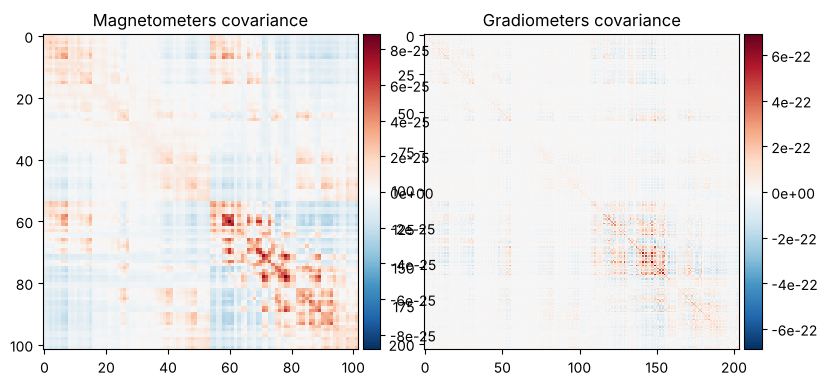

In [4]:
# [FIX 4] noise covariance from a segment that never contains simulated signal
noise_cov = mne.compute_raw_covariance(cov_raw.copy().pick("meg"), method="shrunk", rank="info")
RANK = mne.compute_rank(noise_cov, info=info, rank="info")
print("noise cov rank:", RANK)
noise_cov.plot(info, show_svd=False, show=False);

## 2. Spike waveform
**[FIX 3]** `spike.mat` comes from the sEEG of this case, recorded at 1000 Hz (`sEEG_IZ.ipynb`);
it is used at 1000 Hz, the MEG `sfreq`. The light Gaussian smoothing (σ = 5 samples) of the old
notebook is kept; the artificial 1e-12 white noise added to the waveform is dropped (real noise is added later).

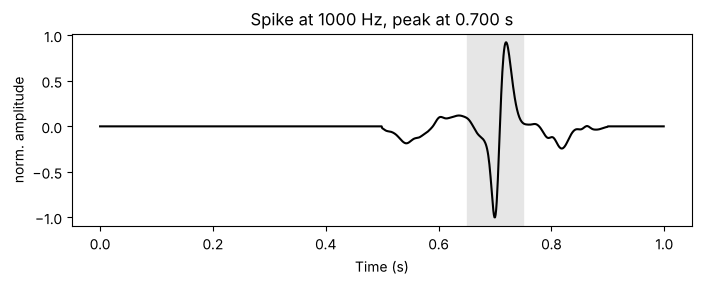

In [5]:
spike = sio.loadmat(HERE / "spike.mat")["spike"].ravel().astype(float)
win = signal.windows.gaussian(51, std=5); win /= win.sum()
spike = np.convolve(spike, win, mode="same")
spike /= np.max(np.abs(spike))                         # unit peak; amplitude set by SNR later

N_T = int(EPOCH_DUR * SFREQ)
ONSET = int(0.5 * SFREQ)                               # spike window 0.5–0.9 s; 0–0.5 s is pure noise
WAVE = np.zeros(N_T); WAVE[ONSET:ONSET + spike.size] = spike
T_PEAK = int(np.argmax(np.abs(WAVE)))
HALF = int(0.05 * SFREQ)                               # analysis window: peak ± 50 ms
AN = slice(T_PEAK - HALF, T_PEAK + HALF + 1)
SUM_W = slice(HALF - int(0.02 * SFREQ), HALF + int(0.02 * SFREQ) + 1)   # ± 20 ms inside AN for amplitudes
times = np.arange(N_T) / SFREQ
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(times, WAVE, "k"); ax.axvspan(times[AN][0], times[AN][-1], color="0.9")
ax.set(xlabel="Time (s)", ylabel="norm. amplitude", title=f"Spike at {SFREQ:.0f} Hz, peak at {times[T_PEAK]:.3f} s")
plt.show()

## 3. Head model and source spaces
* **Inverse model** (the pipeline under evaluation): fsaverage, oct6 cortex + 5 mm volume grid in
  Left/Right Hippocampus and Amygdala, single-shell BEM (ico4, σ = 0.3 S/m) — as before.
* **Simulation model [FIX 11]**: the true sources are placed at exact positions on a 2 mm hippocampal grid,
  i.e. *off* the 5 mm inverse grid, so simulation and reconstruction do not share the source grid.

**[FIX 1]** the true source is defined once (`SourceDef`) and the same coordinates are used for simulation and scoring.

In [6]:
bem_surfs = mne.read_bem_surfaces(Path(SUBJECTS_DIR) / SUBJECT / "bem" / "fsaverage-inner_skull-bem.fif")
for s in bem_surfs: s["sigma"] = 0.3
BEM_FILE = OUT / "inner_skull_1layer-bem-sol.fif"      # cached: delete to recompute
bem = mne.read_bem_solution(BEM_FILE) if BEM_FILE.exists() else mne.make_bem_solution(bem_surfs)
if not BEM_FILE.exists(): mne.write_bem_solution(BEM_FILE, bem)
print("BEM triangles:", bem["surfs"][0]["ntri"])

VOL_LABELS = ["Left-Hippocampus", "Left-Amygdala", "Right-Hippocampus", "Right-Amygdala"]
src_surf = mne.setup_source_space(SUBJECT, spacing="oct6", add_dist=False, subjects_dir=SUBJECTS_DIR)
src_vol = mne.setup_volume_source_space(SUBJECT, pos=5.0, bem=bem, volume_label=VOL_LABELS,
                                        subjects_dir=SUBJECTS_DIR, add_interpolator=False)
src = src_surf + src_vol
t0 = time.time()
FWD_FILE = OUT / f"inverse_model_oct6_vol5-fwd.fif"     # cached: delete to recompute
if FWD_FILE.exists():
    fwd = mne.read_forward_solution(FWD_FILE)
else:
    fwd = mne.make_forward_solution(info, trans=TRANS, src=src, bem=bem, meg=True, eeg=False, mindist=5.0, n_jobs=1)
    mne.write_forward_solution(FWD_FILE, fwd, overwrite=True)
print(fwd, f"({time.time()-t0:.0f} s)")

BEM triangles: 20480


<Forward | MEG channels: 306 | EEG channels: 0 | Source space: Mixed (2 surface, 4 volume) with 8310 vertices | Source orientation: Free> (1 s)


In [7]:
# Bookkeeping of the inverse source space: positions (mm, MRI coords), compartment and ROI membership
src_f = fwd["src"]
pos_mm = np.concatenate([s["rr"][s["vertno"]] for s in src_f]) * 1e3
compart = np.concatenate([[s["seg_name"] if s["type"] == "vol" else ("lh", "rh")[i]] * s["nuse"]
                          for i, s in enumerate(src_f)])
is_vol = np.concatenate([[s["type"] == "vol"] * s["nuse"] for s in src_f])
side = np.where(np.char.startswith(compart.astype(str), "Left") | (compart == "lh"), "L",
                np.where(np.char.startswith(compart.astype(str), "Right") | (compart == "rh"), "R", "?"))
assert not (side == "?").any()

# Mesial-temporal ROI: hippocampus + amygdala (volume) + parahippocampal + entorhinal cortex (aparc)
labels = mne.read_labels_from_annot(SUBJECT, "aparc", subjects_dir=SUBJECTS_DIR)
roi_labels = [l for l in labels if l.name.split("-")[0] in ("parahippocampal", "entorhinal")]
in_roi = is_vol.copy()
off = 0
for hi, s in enumerate(src_f[:2]):
    verts = s["vertno"]
    for l in roi_labels:
        if l.hemi == ["lh", "rh"][hi]:
            in_roi[off + np.where(np.isin(verts, l.vertices))[0]] = True
    off += s["nuse"]
print(pd.Series(compart).value_counts().to_dict())
print("ROI sources: L =", int((in_roi & (side == "L")).sum()), " R =", int((in_roi & (side == "R")).sum()))

{'lh': 4098, 'rh': 4098, 'Right-Hippocampus': 42, 'Left-Hippocampus': 39, 'Right-Amygdala': 19, 'Left-Amygdala': 14}
ROI sources: L = 140  R = 132


In [8]:
# True sources: anterior / middle / posterior hippocampus on the LEFT (2 mm grid), and their exact mirrors x -> -x
import nibabel as nib
aseg = nib.load(Path(SUBJECTS_DIR) / SUBJECT / "mri" / "aseg.mgz")
vox = np.argwhere(np.asarray(aseg.dataobj) == 17)                  # 17 = Left-Hippocampus
vox = vox[(vox % 2 == 1).all(1)]                                   # 2 mm sub-grid, offset from the 5 mm inverse grid
rr_lh = mne.transforms.apply_trans(aseg.header.get_vox2ras_tkr(), vox) / 1e3   # surface RAS, m
ys = np.percentile(rr_lh[:, 1], [80, 50, 20])         # anterior, middle, posterior
cx, cz = np.median(rr_lh[:, 0]), np.median(rr_lh[:, 2])
true_L = np.array([rr_lh[np.argmin((rr_lh[:, 1] - y) ** 2 + (rr_lh[:, 0] - cx) ** 2 + (rr_lh[:, 2] - cz) ** 2)] for y in ys])
MIRROR = np.diag([-1.0, 1.0, 1.0])
true_R = true_L @ MIRROR                               # [FIX 8] exact mirror image
SOURCES = []                                           # [FIX 1] one definition per source
for k, name in enumerate(["ant", "mid", "post"]):
    SOURCES.append(dict(id=f"L_{name}", hemi="L", rr=true_L[k]))
    SOURCES.append(dict(id=f"R_{name}", hemi="R", rr=true_R[k]))
for s in SOURCES: print(s["id"], np.round(s["rr"] * 1e3, 1), "mm")

src_true = mne.setup_volume_source_space(SUBJECT, pos=dict(rr=np.array([s["rr"] for s in SOURCES]),
                                                           nn=np.tile([0, 0, 1.0], (len(SOURCES), 1))))
fwd_true = mne.make_forward_solution(info, trans=TRANS, src=src_true, bem=bem, meg=True, eeg=False, mindist=0.0)
assert fwd_true["nsource"] == len(SOURCES), "a true source fell outside the inner skull"
fwd_true = mne.convert_forward_solution(fwd_true, force_fixed=False)
G_TRUE = fwd_true["sol"]["data"].reshape(len(info["ch_names"]), len(SOURCES), 3)  # (chan, source, xyz)

L_ant [-27. -17. -15.] mm
R_ant [ 27. -17. -15.] mm
L_mid [-27. -23. -15.] mm
R_mid [ 27. -23. -15.] mm
L_post [-27. -33. -13.] mm
R_post [ 27. -33. -13.] mm


## 4. Orientations and SNR
**[FIX 5–8]** Orientations are sampled uniformly (Fibonacci) on the hemisphere of directions, in a
**local frame** at each source: `e_r` = radial from the best-fit sphere origin, `e_a` = tangential
pointing anterior, `e_b = e_r × e_a` (tangential, roughly lateral/vertical). Sign flips are equivalent
for amplitude maps, so a hemisphere covers all distinct orientations. Right sources use the mirror image
of the left orientation (x → −x), so left and right are exact mirrors.

**[FIX 9]** SNR is defined on whitened data: `SNR = max_t ||W b(t)|| / sqrt(rank)`, where `W` is the
noise whitener. A whitened noise channel has unit variance, so this is a unit-free, per-channel amplitude
SNR that weighs magnetometers and gradiometers correctly. It is the **single-trial** SNR; the averaged
evoked has `SNR × sqrt(30) ≈ 5.5 × SNR`.

In [9]:
# Sphere origin fitted to the inner skull (MRI coords) for the radial direction
iskull = bem["surfs"][0]["rr"]
A = np.c_[2 * iskull, np.ones(len(iskull))]; b = (iskull ** 2).sum(1)
ORIGIN = np.linalg.lstsq(A, b, rcond=None)[0][:3]
print("sphere origin (MRI, mm):", np.round(ORIGIN * 1e3, 1))

def local_frame(rr):
    e_r = (rr - ORIGIN) / np.linalg.norm(rr - ORIGIN)
    e_a = np.array([0, 1.0, 0]) - e_r[1] * e_r; e_a /= np.linalg.norm(e_a)
    e_b = np.cross(e_r, e_a)
    return np.c_[e_r, e_a, e_b]                       # columns

def fib_hemisphere(n):
    """n quasi-uniform unit vectors with first coordinate >= 0 (radial component)."""
    k = np.arange(n) + 0.5
    c = k / n                                          # cos(angle to radial), uniform in [0,1] -> uniform area
    phi = np.pi * (1 + 5 ** 0.5) * k
    s = np.sqrt(1 - c ** 2)
    return np.c_[c, s * np.cos(phi), s * np.sin(phi)]

ORI_LOCAL = fib_hemisphere(N_ORI)
ori_tab = pd.DataFrame(dict(ori=np.arange(N_ORI), radial_frac=np.abs(ORI_LOCAL[:, 0]),
                            tang_az_deg=np.degrees(np.arctan2(ORI_LOCAL[:, 2], ORI_LOCAL[:, 1])) % 360))

def orientation_xyz(src_def, k):
    """Unit dipole orientation (MRI xyz) for source src_def and orientation index k (mirrored for R)."""
    left_rr = src_def["rr"] if src_def["hemi"] == "L" else src_def["rr"] @ MIRROR
    q = local_frame(left_rr) @ ORI_LOCAL[k]
    return q if src_def["hemi"] == "L" else MIRROR @ q

# whitener (mag + grad jointly)
W, _ = mne.cov.compute_whitener(noise_cov, info, rank="info")
N_EFF = sum(RANK.values())

def unit_topo(si, k):
    """Field of a 1 Am dipole (chan,)."""
    return G_TRUE[:, si, :] @ orientation_xyz(SOURCES[si], k)

def amp_for_snr(topo, snr):
    """Dipole amplitude (Am) giving single-trial whitened SNR = snr at the spike peak (|WAVE| max = 1)."""
    return snr * np.sqrt(N_EFF) / np.linalg.norm(W @ topo)

ex = np.array([[amp_for_snr(unit_topo(si, k), 1.0) * 1e9 for k in range(N_ORI)] for si in range(len(SOURCES))])
print(f"Dipole moment needed for single-trial SNR=1: median {np.median(ex):.0f} nAm "
      f"(range {ex.min():.0f}–{ex.max():.0f}) — radial orientations need far more")

sphere origin (MRI, mm): [  0.4 -22.9   8.6]
Dipole moment needed for single-trial SNR=1: median 234 nAm (range 118–574) — radial orientations need far more


## 5. Inverse operators and fast application
**[FIX 11]** One joint mag+grad inverse whitened by `noise_cov` (no more averaging of two separate
solutions). The inverse is linear, so `estimate = K · (signal + noise)`: the kernel `K` is assembled once
per method and applied to the signal and noise parts separately; the result is verified against
`apply_inverse` below.

In [10]:
inv = mne.minimum_norm.make_inverse_operator(info, fwd, noise_cov, loose="auto", depth=0.8, rank="info")
KERN = {}
for m in METHODS:
    inv_p = mne.minimum_norm.prepare_inverse_operator(inv, nave=N_EPOCHS, lambda2=LAMBDA2, method=m)
    K, nn, _, _ = _assemble_kernel(inv_p, None, m, None)
    KERN[m] = (K, nn)
N_SRC = fwd["nsource"]
print({m: KERN[m][0].shape for m in METHODS})

def apply_kernel(m, data):
    K, nn = KERN[m]
    sol = combine_xyz(K @ data) if K.shape[0] == 3 * N_SRC else np.abs(K @ data)
    if nn is not None:
        sol = sol * nn
    return sol                                          # (n_src, n_times) amplitude

# verification against MNE's own apply_inverse
_test = mne.EvokedArray(rng.standard_normal((len(info["ch_names"]), 20)) * 1e-13, info, nave=N_EPOCHS)
for m in METHODS:
    ref = mne.minimum_norm.apply_inverse(_test, inv, LAMBDA2, m).data
    assert np.allclose(ref, apply_kernel(m, _test.data), rtol=1e-6, atol=1e-12 * np.abs(ref).max()), m
print("kernel application matches apply_inverse for", METHODS)

{'MNE': (24930, 306), 'dSPM': (24930, 306), 'sLORETA': (24930, 306)}


kernel application matches apply_inverse for ['MNE', 'dSPM', 'sLORETA']


## 6. Noise realisations
**[FIX 10]** Each repetition averages `N_EPOCHS` epochs drawn at random onsets from the 300 s pool;
repetitions are independent. The same noise draws are reused across orientations, positions and SNRs
within a repetition (paired design), so differences between conditions are not noise draws.

In [11]:
def draw_noise_average(rng, n_ep=N_EPOCHS, length=N_T):
    on = rng.integers(0, POOL.shape[1] - length, n_ep)
    return np.mean([POOL[:, o:o + length] for o in on], axis=0)

NOISE_REPS = [draw_noise_average(rng)[:, AN] for _ in range(N_REPS)]

## 7. Metrics  [FIX 12]
For each reconstruction, the source amplitude is averaged over ±20 ms around the spike peak.
* **LI_roi** = (A_true − A_other)/(A_true + A_other), A = mean amplitude over the mesial-temporal ROI of
  each side (hippocampus, amygdala, parahippocampal, entorhinal). Mean, not count → independent of source density. Range −1…1, >0 = correct.
* **LI_hemi**: same over all sources of each hemisphere.
* **peak_correct**: the global amplitude peak is in the true hemisphere; **peak_err_mm**: distance from peak to the true source (replaces the centroid distance).
* **old_ratio / old_LIcount**: the old thresholded vertex-count metric (0.8 cortex / 0.2 volume, MNE), computed safely, for comparison only.

In [12]:
WAVE_AN = WAVE[AN]
src_side = side
def metrics(amp, true_hemi, true_rr_mm):
    a = amp[:, SUM_W].mean(1)
    other = "R" if true_hemi == "L" else "L"
    def li(mask):
        at = a[mask & (src_side == true_hemi)].mean(); ao = a[mask & (src_side == other)].mean()
        return (at - ao) / (at + ao)
    pk = int(np.argmax(a))
    return dict(LI_roi=li(in_roi), LI_hemi=li(np.ones_like(in_roi)),
                peak_correct=src_side[pk] == true_hemi, peak_in_roi=bool(in_roi[pk]),
                peak_err_mm=float(np.linalg.norm(pos_mm[pk] - true_rr_mm)))

def old_metric(amp, true_hemi):
    p = amp.max(1); p = p / p.max()
    act = np.where(is_vol, p >= 0.2, p >= 0.8)
    t = int((act & (src_side == true_hemi)).sum()); o = int((act & (src_side != true_hemi)).sum())
    return dict(old_ratio=t / o if o else np.nan, old_LIcount=(t - o) / (t + o))

## 8. Main simulation

In [13]:
RERUN_SIM = False                                  # results are cached; set True to recompute
res_file = OUT / f"sim_results_{RUN_TAG}.csv"
rows = []
t0 = time.time()
# kernel · noise, computed once per method and repetition (noise must enter BEFORE the amplitude |.|)
KNs = {m: [KERN[m][0] @ n for n in NOISE_REPS] for m in METHODS}
for si, sdef in enumerate(SOURCES if (RERUN_SIM or not res_file.exists()) else []):
    true_mm = sdef["rr"] * 1e3
    for k in range(N_ORI):
        q = orientation_xyz(sdef, k)
        topo = G_TRUE[:, si, :] @ q
        KS = {m: KERN[m][0] @ topo for m in METHODS}               # kernel · unit topography (signal part)
        for snr in SNRS:
            amp_q = amp_for_snr(topo, snr)
            for r in range(N_REPS):
                for m in METHODS:
                    K, nn = KERN[m]
                    lin = amp_q * np.outer(KS[m], WAVE_AN) + KNs[m][r]   # K·(signal+noise)
                    amp = combine_xyz(lin) if K.shape[0] == 3 * N_SRC else np.abs(lin)
                    if nn is not None: amp = amp * nn
                    row = dict(source=sdef["id"], hemi=sdef["hemi"], ori=k, snr=snr, rep=r, method=m,
                               moment_nAm=amp_q * 1e9, qx=abs(q[0]), qy=abs(q[1]), qz=abs(q[2]))
                    row.update(metrics(amp, sdef["hemi"], true_mm))
                    if m == "MNE": row.update(old_metric(amp, sdef["hemi"]))
                    rows.append(row)
    print(f"{sdef['id']} done, {time.time()-t0:.0f} s")
if rows:
    res = pd.DataFrame(rows).merge(ori_tab, on="ori")
    res.to_csv(res_file, index=False)        # [FIX 2] the plots below read exactly this file
print(res_file, "rows:", len(pd.read_csv(res_file)))

/home/claude/sim/run/results_261013/sim_results_261013.csv rows: 32400


## 9. Results — lateralisation vs SNR, by method and hemisphere

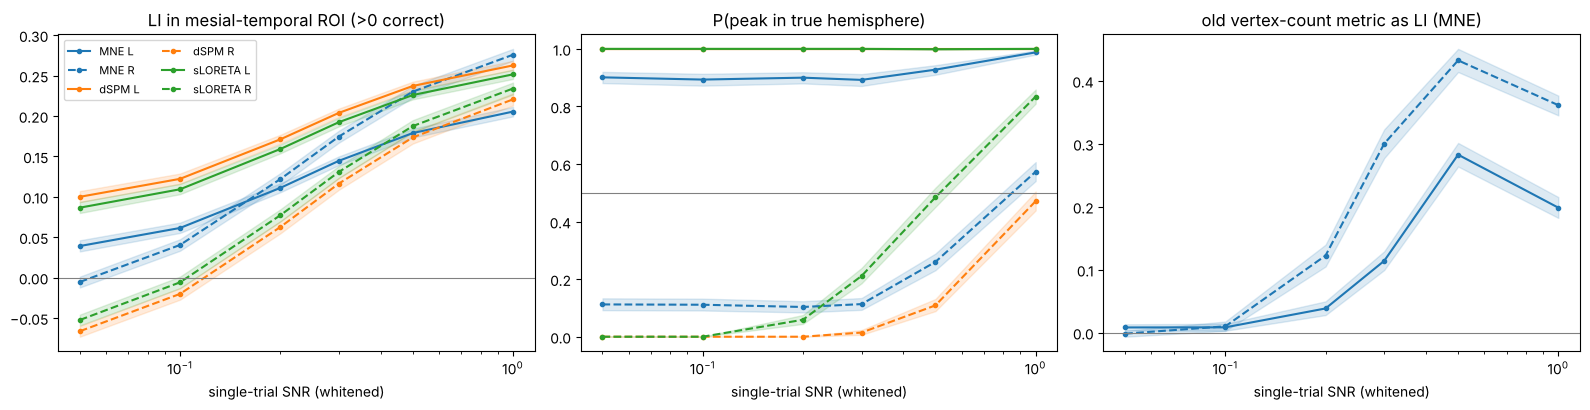

LI_roi  P_correct_LIroi  P_peak_correct  peak_err_mm
method  hemi snr                                                       
MNE     L    0.05   0.039            0.713           0.901      140.658
             0.10   0.061            0.737           0.893      140.658
             0.20   0.111            0.903           0.900      140.658
             0.30   0.144            0.976           0.892      140.658
             0.50   0.179            0.999           0.928      140.658
             1.00   0.205            1.000           0.988      127.101
        R    0.05  -0.005            0.394           0.112      143.731
             0.10   0.040            0.598           0.111      143.731
             0.20   0.122            0.828           0.103      143.731
             0.30   0.175            0.941           0.113      143.731
             0.50   0.230            0.992           0.260      139.627
             1.00   0.276            1.000           0.573      124.877
dSPM    L    0.05   0.100            0.813           1.000      113.455
             0.10   0.122            0.864           1.000      113.455
             0.20   0.171            0.976           1.000      113.477
             0.30   0.204            0.997           1.000      113.160
             0.50   0.237            1.000           1.000      115.091
             1.00   0.263            1.000           1.000      113.749
        R    0.05  -0.066            0.234           0.000      137.472
             0.10  -0.020            0.398           0.000      137.472
             0.20   0.062            0.672           0.000      137.102
             0.30   0.116            0.813           0.014      137.102
             0.50   0.173            0.951           0.109      135.798
             1.00   0.221            0.996           0.471      126.816
sLORETA L    0.05   0.086            0.783           1.000       94.143
             0.10   0.109            0.833           1.000       94.143
             0.20   0.159            0.968           1.000       94.143
             0.30   0.192            0.993           1.000       92.695
             0.50   0.226            1.000           0.999       91.688
             1.00   0.251            1.000           1.000       52.043
        R    0.05  -0.053            0.267           0.000      124.050
             0.10  -0.006            0.460           0.000      124.050
             0.20   0.077            0.713           0.059      124.050
             0.30   0.131            0.853           0.211      122.778
             0.50   0.187            0.960           0.484      118.164
             1.00   0.234            0.997           0.834       52.070

In [14]:
res = pd.read_csv(res_file)
def ci(x):
    x = np.asarray(x, float); bs = np.random.default_rng(0).choice(x, (2000, x.size)).mean(1)
    return pd.Series(dict(mean=x.mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
for ax, metric, lab in zip(axes, ["LI_roi", "peak_correct", "old_LIcount"],
                           ["LI in mesial-temporal ROI (>0 correct)", "P(peak in true hemisphere)", "old vertex-count metric as LI (MNE)"]):
    for m, c in zip(METHODS, ["C0", "C1", "C2"]):
        for h, ls in [("L", "-"), ("R", "--")]:
            if metric == "old_LIcount" and m != "MNE": continue
            d = res[(res.method == m) & (res.hemi == h)].groupby("snr")[metric].apply(ci).unstack()
            ax.plot(d.index, d["mean"], ls, color=c, marker="o", ms=3, label=f"{m} {h}")
            ax.fill_between(d.index, d["lo"], d["hi"], color=c, alpha=0.15)
    ax.axhline(0.5 if metric == "peak_correct" else 0, color="0.5", lw=0.8)
    ax.set(xscale="log", xlabel="single-trial SNR (whitened)", title=lab)
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); fig.savefig(OUT / f"fig_snr_{RUN_TAG}.png", dpi=150); plt.show()

summary = (res.groupby(["method", "hemi", "snr"])
              .agg(LI_roi=("LI_roi", "mean"), P_correct_LIroi=("LI_roi", lambda x: (x > 0).mean()),
                   P_peak_correct=("peak_correct", "mean"), peak_err_mm=("peak_err_mm", "median"))
              .round(3))
summary.to_csv(OUT / f"summary_{RUN_TAG}.csv")
summary

## 10. Results — orientation dependence (the bias seen in the old cell 48)
Each panel: correct-lateralisation rate (LI_roi > 0) per orientation at SNR ≥ 0.3, plotted against the
radial fraction of the dipole and against its share along MRI x (left–right). If the old bias was produced
by the method and metric, it should shrink or disappear for dSPM/sLORETA with the ROI LI.

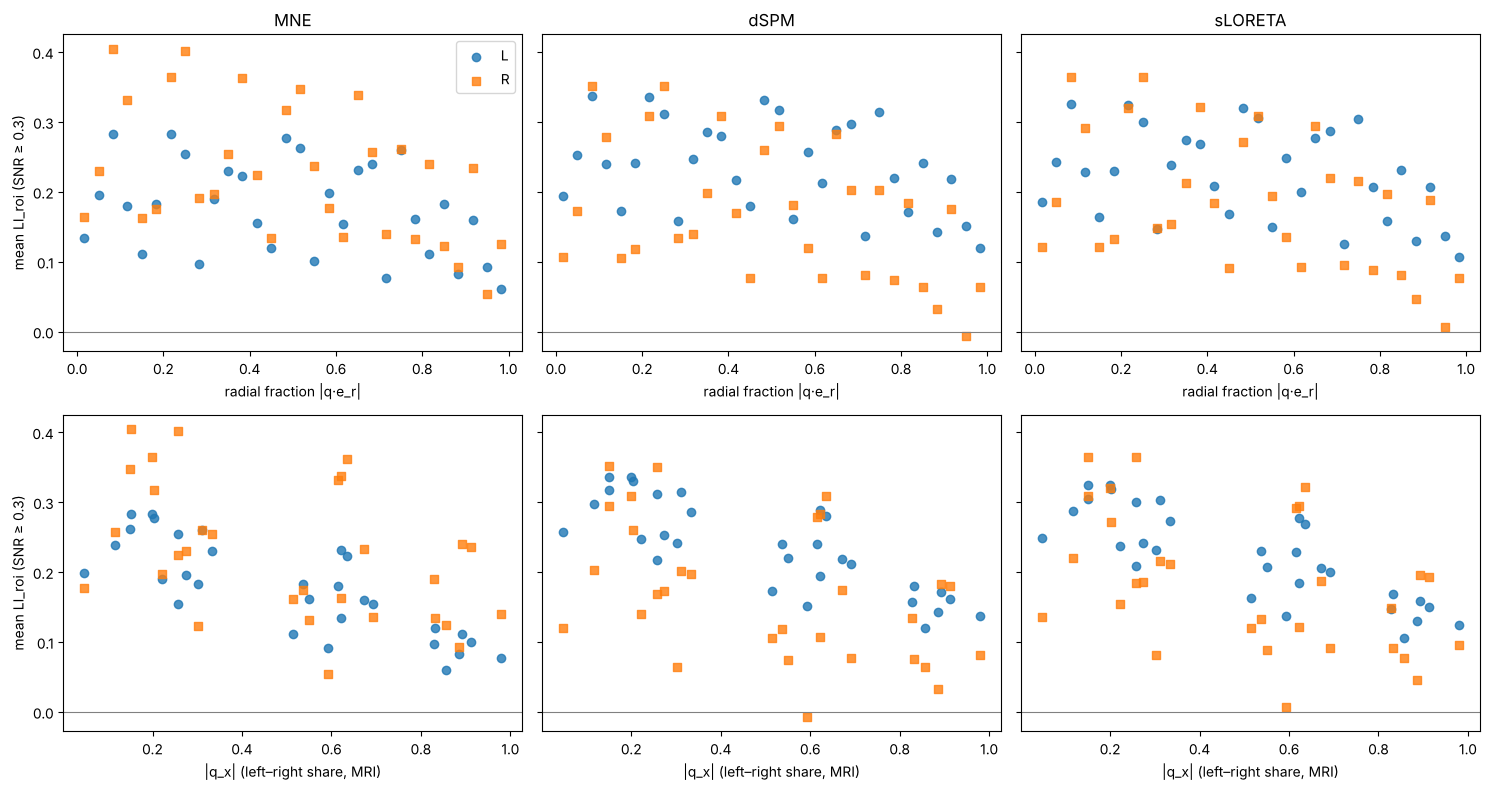

var                    qx    qy    qz  radial_frac
metric      method                                
LI_roi      MNE     -0.45  0.50 -0.05        -0.30
            dSPM    -0.44  0.48 -0.04        -0.30
            sLORETA -0.46  0.49 -0.04        -0.31
old_LIcount MNE     -0.19  0.18  0.01        -0.10

In [15]:
hi_snr = res[res.snr >= 0.3]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for j, m in enumerate(METHODS):
    d = hi_snr[hi_snr.method == m].groupby(["ori", "hemi"]).agg(LI=("LI_roi", "mean"), radial=("radial_frac", "first"),
                                                                   qx=("qx", "mean")).reset_index()
    for h, mk in [("L", "o"), ("R", "s")]:
        dd = d[d.hemi == h]
        axes[0, j].scatter(dd.radial, dd.LI, marker=mk, label=h, alpha=0.8)
        axes[1, j].scatter(dd.qx, dd.LI, marker=mk, label=h, alpha=0.8)
    axes[0, j].set(title=m, xlabel="radial fraction |q·e_r|")
    axes[1, j].set(xlabel="|q_x| (left–right share, MRI)")
    for a in axes[:, j]: a.axhline(0, color="0.5", lw=0.8)
axes[0, 0].set_ylabel("mean LI_roi (SNR ≥ 0.3)"); axes[1, 0].set_ylabel("mean LI_roi (SNR ≥ 0.3)")
axes[0, 0].legend()
plt.tight_layout(); fig.savefig(OUT / f"fig_orientation_{RUN_TAG}.png", dpi=150); plt.show()

# quantify: correlation of LI_roi (and of the old metric) with |q_x|, |q_y|, |q_z| and radial fraction
corr_rows = []
for m in METHODS:
    d = hi_snr[hi_snr.method == m]
    for v in ["qx", "qy", "qz", "radial_frac"]:
        corr_rows.append(dict(method=m, metric="LI_roi", var=v, r=np.corrcoef(d[v], d.LI_roi)[0, 1]))
d = hi_snr[hi_snr.method == "MNE"]
for v in ["qx", "qy", "qz", "radial_frac"]:
    corr_rows.append(dict(method="MNE", metric="old_LIcount", var=v, r=np.corrcoef(d[v], d.old_LIcount)[0, 1]))
corr = pd.DataFrame(corr_rows).pivot_table(index=["metric", "method"], columns="var", values="r").round(2)
corr.to_csv(OUT / f"orientation_correlations_{RUN_TAG}.csv"); corr

## 11. Mirror check (left vs right)
Left and right sources are exact mirror images with mirrored orientations and the same noise draws.
Any systematic difference therefore comes from asymmetry of the sensors/head model or of the noise.

In [16]:
mir = (res.assign(pair=res.source.str[2:])
          .pivot_table(index=["pair", "ori", "snr", "rep", "method"], columns="hemi", values="LI_roi").reset_index())
mir["diff_L_minus_R"] = mir.L - mir.R
mirror_tab = mir.groupby(["method", "snr"]).diff_L_minus_R.apply(ci).unstack().round(3)
mirror_tab.to_csv(OUT / f"mirror_check_{RUN_TAG}.csv"); mirror_tab

mean     lo     hi
method  snr                      
MNE     0.05  0.044  0.031  0.058
        0.10  0.021  0.009  0.033
        0.20 -0.011 -0.020 -0.001
        0.30 -0.030 -0.037 -0.023
        0.50 -0.051 -0.057 -0.046
        1.00 -0.070 -0.075 -0.066
dSPM    0.05  0.166  0.153  0.180
        0.10  0.142  0.131  0.154
        0.20  0.109  0.100  0.118
        0.30  0.087  0.080  0.095
        0.50  0.064  0.058  0.069
        1.00  0.042  0.037  0.047
sLORETA 0.05  0.139  0.126  0.152
        0.10  0.115  0.104  0.127
        0.20  0.082  0.073  0.091
        0.30  0.061  0.054  0.069
        0.50  0.038  0.033  0.044
        1.00  0.018  0.013  0.022

## 12. Dipole fit (subset)
Equivalent-current-dipole fit at the spike peak (clinical standard for IEDs). Each BEM fit takes ~12 s,
so a subset is run: middle hippocampus L and R, every 2nd orientation (15), noise-free / SNR 0.3 / SNR 1,
one noise repetition.
The fit uses a **decimated BEM** (5120 triangles) rather than the 20480-triangle BEM used to simulate,
so the fit model differs from the simulation model (no inverse crime).
A single-sphere model was tested and rejected: even without noise it mislocalised these basal sources by
40–60 mm (the fsaverage inner skull is far from spherical under the temporal lobes).

In [17]:
trans_obj = mne.read_trans(Path(SUBJECTS_DIR) / SUBJECT / "bem" / "fsaverage-trans.fif")
head_to_mri = trans_obj if trans_obj["from"] == mne.io.constants.FIFF.FIFFV_COORD_HEAD else mne.transforms.invert_transform(trans_obj)
BEM4_FILE = OUT / "bem_ico4_dipfit-sol.fif"
if BEM4_FILE.exists():
    bem4 = mne.read_bem_solution(BEM4_FILE)
else:
    s0 = bem["surfs"][0]
    rr4, tris4 = mne.decimate_surface(s0["rr"], s0["tris"], 5120)
    bem4 = mne.make_bem_solution([dict(rr=rr4, tris=tris4, id=s0["id"], coord_frame=s0["coord_frame"], sigma=0.3)])
    mne.write_bem_solution(BEM4_FILE, bem4)

dip_file = OUT / f"dipole_results_{RUN_TAG}.csv"
rows_d = []
t0 = time.time()
pk = HALF
DIP_SNRS = [np.inf, 0.3, 1.0]           # inf = noise-free (tests the fit itself)
todo = [i for i, s in enumerate(SOURCES) if s["id"].endswith("mid")] if (RERUN_SIM or not dip_file.exists()) else []
for si in todo:
    sdef = SOURCES[si]
    for k in range(0, N_ORI, 2):
        topo = unit_topo(si, k)
        for snr in DIP_SNRS:
            a = amp_for_snr(topo, 1.0 if np.isinf(snr) else snr)
            noise = 0 if np.isinf(snr) else NOISE_REPS[0][:, pk - 1:pk + 2]
            ev = mne.EvokedArray(a * topo[:, None] * WAVE_AN[None, pk - 1:pk + 2] + noise, info, tmin=-0.001, nave=N_EPOCHS)
            dip, _ = mne.fit_dipole(ev.crop(0, 0), noise_cov, bem4, trans=trans_obj, rank="info", n_jobs=2)
            pos_mri = mne.transforms.apply_trans(head_to_mri, dip.pos[0]) * 1e3   # head -> MRI coords
            rows_d.append(dict(source=sdef["id"], hemi=sdef["hemi"], ori=k, snr=snr,
                               correct=bool(np.sign(pos_mri[0]) == np.sign(sdef["rr"][0])),
                               err_mm=float(np.linalg.norm(pos_mri - sdef["rr"] * 1e3)), gof=float(dip.gof[0])))
        print(sdef["id"], k, f"{time.time()-t0:.0f} s")
if rows_d:
    pd.DataFrame(rows_d).merge(ori_tab, on="ori").to_csv(dip_file, index=False)
dip_res = pd.read_csv(dip_file)
dip_tab = dip_res.groupby(["hemi", "snr"]).agg(P_correct=("correct", "mean"), err_mm=("err_mm", "median"),
                                               err_mm_p90=("err_mm", lambda x: np.percentile(x, 90)),
                                               gof=("gof", "median")).round(2)
dip_tab.to_csv(OUT / f"dipole_summary_{RUN_TAG}.csv"); dip_tab

P_correct  err_mm  err_mm_p90    gof
hemi snr                                      
L    0.3       0.80   73.55       90.57  78.47
     1.0       0.33   71.97       94.29  82.65
     inf       1.00   11.10       42.76  97.61
R    0.3       0.40   86.75       93.16  74.40
     1.0       0.87   23.47       63.26  84.36
     inf       1.00   10.41       15.37  95.03

## 13. Bias from the spatial distribution of the noise
Four checks:
1. **Sensor-level noise power**, left vs right channels (magnetometers and gradiometer pairs).
2. **Artefact sources**: lateralisation of ECG-correlated noise (the heart is on the left).
3. **Noise-weighted detectability** of mirrored source pairs: `||W G q||` (whitened) vs `||G q||` (raw). With
   exact mirror geometry, a whitened L/R difference that is absent in the raw gain comes from the noise.
4. **Sham reconstructions**: noise only (no spike) through each inverse; the LI of pure noise is the bias floor.

In [18]:
ch_x = np.array([c["loc"][0] for c in info["chs"]])
ch_type = np.array(info.get_channel_types())
std = POOL.std(1)
nb = {}
for t in ["mag", "grad"]:
    sel = ch_type == t
    L, R = sel & (ch_x < -0.02), sel & (ch_x > 0.02)
    pL, pR = (std[L] ** 2).mean(), (std[R] ** 2).mean()
    nb[t] = dict(n_left=int(L.sum()), n_right=int(R.sum()), LI_power=(pL - pR) / (pL + pR))
# frequency-resolved
f, P = signal.welch(POOL[:, :int(120 * SFREQ)], fs=SFREQ, nperseg=2048)
bands = {"delta 1-4": (1, 4), "theta 4-8": (4, 8), "alpha 8-13": (8, 13), "beta 13-30": (13, 30), "gamma 30-80": (30, 80)}
band_li = {}
for t in ["mag", "grad"]:
    sel = ch_type == t
    L, R = sel & (ch_x < -0.02), sel & (ch_x > 0.02)
    band_li[t] = {b: float((P[L][:, (f >= lo) & (f < hi)].mean() - P[R][:, (f >= lo) & (f < hi)].mean()) /
                           (P[L][:, (f >= lo) & (f < hi)].mean() + P[R][:, (f >= lo) & (f < hi)].mean()))
                  for b, (lo, hi) in bands.items()}
noise_LR = pd.DataFrame(band_li).T.assign(broadband=[nb[t]["LI_power"] for t in ["mag", "grad"]]).round(3)
print("LI of noise power = (L-R)/(L+R) over channels |x|>2 cm"); noise_LR

LI of noise power = (L-R)/(L+R) over channels |x|>2 cm


,delta 1-4,theta 4-8,alpha 8-13,beta 13-30,gamma 30-80,broadband
mag,0.143,0.138,0.195,0.193,0.226,0.175
grad,0.240,0.240,0.354,0.321,0.332,0.310


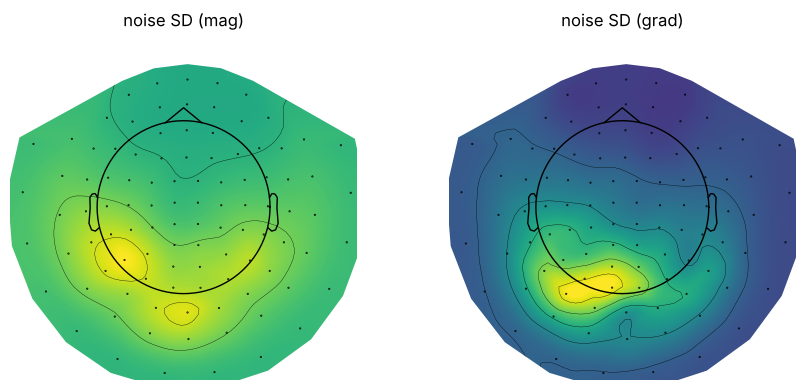

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ev_std = mne.EvokedArray(std[:, None], info, tmin=0)        # per-channel noise SD (grad pairs merged by RMS)
for ax, t in zip(axes, ["mag", "grad"]):
    ev_std.plot_topomap(times=0, ch_type=t, axes=ax, colorbar=False, show=False, cmap="viridis",
                        time_format="", vlim=(None, None))
    ax.set_title(f"noise SD ({t})")
plt.tight_layout(); fig.savefig(OUT / f"fig_noise_topo_{RUN_TAG}.png", dpi=150); plt.show()

In [20]:
# ECG-correlated noise: share of each channel's variance explained by the ECG channel, L vs R
ecg = pool_raw.get_data(picks="ecg", stop=int(120 * SFREQ))     # first 120 s (memory)
if ecg.size:
    e = signal.sosfiltfilt(signal.butter(4, [5, 30], btype="band", fs=SFREQ, output="sos"), ecg[0])
    Mf = signal.sosfiltfilt(signal.butter(4, [5, 30], btype="band", fs=SFREQ, output="sos"), POOL[:, :len(e)], axis=1)
    r2 = np.array([np.corrcoef(e, Mf[i])[0, 1] ** 2 for i in range(len(Mf))])
    ecg_tab = pd.DataFrame({t: dict(left=r2[(ch_type == t) & (ch_x < -0.02)].mean(),
                                    right=r2[(ch_type == t) & (ch_x > 0.02)].mean()) for t in ["mag", "grad"]}).T.round(4)
    print("mean R² with ECG (5–30 Hz)"); print(ecg_tab)

mean R² with ECG (5–30 Hz)
        left   right
mag   0.0078  0.0081
grad  0.0047  0.0038


In [21]:
# Noise-weighted detectability of mirrored pairs, per orientation
det = []
for name in ["ant", "mid", "post"]:
    iL = [i for i, s in enumerate(SOURCES) if s["id"] == f"L_{name}"][0]
    iR = [i for i, s in enumerate(SOURCES) if s["id"] == f"R_{name}"][0]
    for k in range(N_ORI):
        gL, gR = unit_topo(iL, k), unit_topo(iR, k)
        mags, grads = ch_type == "mag", ch_type == "grad"
        det.append(dict(pair=name, ori=k,
                        white_dB=20 * np.log10(np.linalg.norm(W @ gL) / np.linalg.norm(W @ gR)),
                        raw_mag_dB=20 * np.log10(np.linalg.norm(gL[mags]) / np.linalg.norm(gR[mags])),
                        raw_grad_dB=20 * np.log10(np.linalg.norm(gL[grads]) / np.linalg.norm(gR[grads]))))
det = pd.DataFrame(det).merge(ori_tab, on="ori")
det.to_csv(OUT / f"detectability_LR_{RUN_TAG}.csv", index=False)
print("L/R gain ratio in dB (positive = left source stronger). Raw = geometry only; whitened = geometry + noise")
det[["white_dB", "raw_mag_dB", "raw_grad_dB"]].describe().round(2)

L/R gain ratio in dB (positive = left source stronger). Raw = geometry only; whitened = geometry + noise


,white_dB,raw_mag_dB,raw_grad_dB
count,90.00,90.00,90.00
mean,1.17,0.40,0.66
std,1.41,0.16,0.19
min,-3.77,-0.30,-0.16
25%,0.71,0.34,0.59
50%,1.42,0.42,0.69
75%,2.08,0.49,0.77
max,4.10,0.76,1.12


In [22]:
# Sham: noise-only averages through each inverse
sham = []
rng_s = np.random.default_rng(SEED + 1)
for i in range(N_SHAM):
    n = draw_noise_average(rng_s)[:, AN]
    for m in METHODS:
        a = apply_kernel(m, n)[:, SUM_W].mean(1)
        AL, AR = a[in_roi & (src_side == "L")].mean(), a[in_roi & (src_side == "R")].mean()
        HL, HR = a[src_side == "L"].mean(), a[src_side == "R"].mean()
        sham.append(dict(i=i, method=m, LI_roi_LminusR=(AL - AR) / (AL + AR), LI_hemi_LminusR=(HL - HR) / (HL + HR),
                         peak_left=src_side[np.argmax(a)] == "L"))
sham = pd.DataFrame(sham)
sham.to_csv(OUT / f"sham_{RUN_TAG}.csv", index=False)
sham_tab = sham.groupby("method").agg(LI_roi_mean=("LI_roi_LminusR", "mean"), LI_roi_sd=("LI_roi_LminusR", "std"),
                                      P_LIroi_left=("LI_roi_LminusR", lambda x: (x > 0).mean()),
                                      LI_hemi_mean=("LI_hemi_LminusR", "mean"), P_peak_left=("peak_left", "mean")).round(3)
sham_tab

,LI_roi_mean,LI_roi_sd,P_LIroi_left,LI_hemi_mean,P_peak_left
method,,,,,
MNE,-0.021,0.121,0.440,0.042,0.820
dSPM,0.039,0.121,0.645,0.123,0.995
sLORETA,0.024,0.122,0.600,0.050,0.930


In [23]:
# Where does pure noise peak? aparc label of the sham peak source (cortex) or volume structure
lab_of = np.array(compart, dtype=object)
off = 0
for hi, s_ in enumerate(src_f[:2]):
    for l in labels:
        if l.hemi == ("lh", "rh")[hi]:
            lab_of[off + np.where(np.isin(s_["vertno"], l.vertices))[0]] = l.name
    off += s_["nuse"]
rng_p = np.random.default_rng(SEED + 2)
pk_rows = []
for i in range(100):
    n = draw_noise_average(rng_p)[:, AN]
    for m in METHODS:
        a = apply_kernel(m, n)[:, SUM_W].mean(1)
        pk_rows.append(dict(method=m, label=lab_of[np.argmax(a)]))
sham_peaks = pd.DataFrame(pk_rows).groupby("method").label.value_counts(normalize=True).groupby(level=0).head(4).round(2)
sham_peaks

method   label                  
MNE      superiorfrontal-lh         0.77
         superiorfrontal-rh         0.16
         medialorbitofrontal-lh     0.02
         lateralorbitofrontal-lh    0.02
dSPM     postcentral-lh             0.67
         supramarginal-lh           0.33
sLORETA  supramarginal-lh           0.77
         postcentral-lh             0.12
         inferiorparietal-lh        0.02
         inferiorparietal-rh        0.02
Name: proportion, dtype: float64

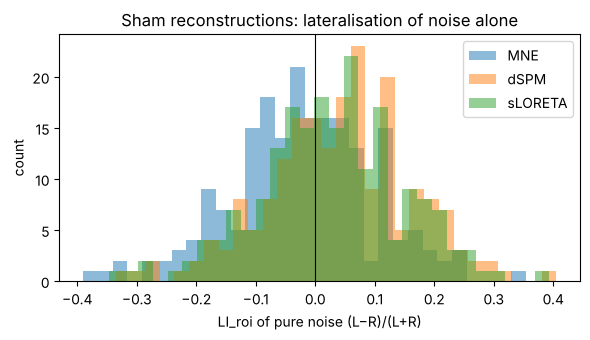

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for m in METHODS:
    ax.hist(sham[sham.method == m].LI_roi_LminusR, bins=30, alpha=0.5, label=m)
ax.axvline(0, color="k", lw=0.8); ax.set(xlabel="LI_roi of pure noise (L−R)/(L+R)", ylabel="count",
                                        title="Sham reconstructions: lateralisation of noise alone")
ax.legend(); plt.tight_layout(); fig.savefig(OUT / f"fig_sham_{RUN_TAG}.png", dpi=150); plt.show()

## 14. Save
All tables are in `results_261013/`. `config_261013.json` records the parameters of this run.

In [25]:
print(sorted(p.name for p in OUT.iterdir()))

['bem_ico4_dipfit-sol.fif', 'config_261013.json', 'detectability_LR_261013.csv', 'dipole_results_261013.csv', 'dipole_summary_261013.csv', 'fig_noise_topo_261013.png', 'fig_orientation_261013.png', 'fig_sham_261013.png', 'fig_snr_261013.png', 'inner_skull_1layer-bem-sol.fif', 'inverse_model_oct6_vol5-fwd.fif', 'mirror_check_261013.csv', 'orientation_correlations_261013.csv', 'sham_261013.csv', 'sim_results_261013.csv', 'summary_261013.csv']
